# Can signatures detect our path problems?

Test signatures on real data, deliberately damaged data, and saved models.
Use the `sandbox/.venv` kernel and run from the top. No models are trained and
no validation or test data are used.

The score compares average signature features, following the idea in
[Sig-WGAN](https://arxiv.org/html/2111.01207v1). The feature scaling and controls
below are our diagnostic choices.

In [1]:
from pathlib import Path
from math import factorial
from importlib.metadata import version
import json
import os
import sys

os.environ["JAX_PLATFORMS"] = "cpu"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "sandbox/4stocks_experiment/sde_gan.py").is_file())
experiment_dir = root / "sandbox/4stocks_experiment"
if str(experiment_dir) not in sys.path:
    sys.path.insert(0, str(experiment_dir))
from sde_gan import SDEGAN

SAMPLE_SEED = 100
N_GENERATED = 1000
BATCH_SIZE = 256
BATCH_REPEATS = 100
BATCH_SEED = 2026
DEPTHS = [2, 3]
FEATURE_STD_MIN = 1e-10
out_dir = experiment_dir / "results/signature_diagnostics"
out_dir.mkdir(parents=True, exist_ok=True)

## Load the real training windows

Read the original returns to keep exact zeros. Use the saved training scaler
for every group so the comparison cannot hide differences by rescaling each path.

In [2]:
reference_metadata = json.loads((experiment_dir / "data/preprocessing.json").read_text())
STOCKS = reference_metadata["stock_order"]
mean = np.asarray(reference_metadata["training_mean"])
std = np.asarray(reference_metadata["training_std"])
frame = pd.read_csv(experiment_dir / "data/train_returns.csv", index_col="Date",
                    parse_dates=["Date"]).loc[:, STOCKS]
dates = pd.read_csv(experiment_dir / "data/window_dates.csv",
                    parse_dates=["start_date", "end_date"])
dates = dates.loc[dates.split.eq("train")].sort_values("window_index")
real = np.stack([frame.loc[row.start_date:row.end_date].to_numpy()
                 for row in dates.itertuples()])
assert real.shape[1:] == (20, 4) and np.isfinite(real).all()
with np.load(experiment_dir / "data/prepared_windows.npz", allow_pickle=False) as saved:
    np.testing.assert_allclose((np.log1p(real) - mean) / std, saved["train_windows"],
                               rtol=1e-6, atol=1e-6)
print(f"Training windows: {len(real):,}; sessions per window: {real.shape[1]}")

Training windows: 1,679; sessions per window: 20


## Make known bad examples

Halve returns to create low volatility. Sort by each stock while moving whole
four-stock rows together to change time order without changing return values,
volatility, or same-day cross-stock relationships. Check that the ACF really changes.

In [3]:
def return_acf(paths: np.ndarray) -> np.ndarray:
    """Pool within-path pairs at lags 1–5; never join different paths."""
    return np.array([
        [np.corrcoef(paths[:, :-lag, j].ravel(), paths[:, lag:, j].ravel())[0, 1]
         for j in range(4)] for lag in range(1, 6)
    ])


pools = {"real": real, "half_volatility": real * 0.5}
labels = {"real": "Real batches", "half_volatility": "Half volatility"}
np.testing.assert_allclose(pools["half_volatility"].std(axis=(0, 1), ddof=1),
                           0.5 * real.std(axis=(0, 1), ddof=1))
real_acf = return_acf(real)
for j, stock in enumerate(STOCKS):
    order = np.argsort(real[:, :, j], axis=1, kind="stable")
    reordered = np.take_along_axis(real, order[:, :, None], axis=1)
    inverse = np.argsort(order, axis=1)
    np.testing.assert_array_equal(np.take_along_axis(reordered, inverse[:, :, None], axis=1), real)
    np.testing.assert_allclose(reordered.std(axis=(0, 1), ddof=1), real.std(axis=(0, 1), ddof=1))
    np.testing.assert_allclose(np.cov(reordered.reshape(-1, 4), rowvar=False),
                               np.cov(real.reshape(-1, 4), rowvar=False), atol=1e-14)
    np.testing.assert_allclose(np.prod(1 + reordered.mean(axis=2), axis=1),
                               np.prod(1 + real.mean(axis=2), axis=1))
    assert return_acf(reordered)[0, j] > real_acf[0, j] + 0.2
    key = f"sorted_{j}"
    pools[key] = reordered
    labels[key] = f"Sorted by {stock}"
print("Passed: half volatility; unchanged values, volatility, covariance, and terminal portfolio returns after sorting.")

Passed: half volatility; unchanged values, volatility, covariance, and terminal portfolio returns after sorting.


## Load the existing models

Sample each saved baseline, weight-10, and weight-30 model with the same seed.
This lets us compare their known failures with the deliberately damaged data.

In [4]:
model_records = []
for group, folder in [("baseline", ""), ("weight10", "temporal_penalty"),
                      ("weight30", "temporal_penalty_30")]:
    run_dirs = sorted((experiment_dir / "results/sde_gan" / folder).glob("seed_*"))
    if not run_dirs:
        raise FileNotFoundError(f"No saved {group} models")
    for directory in run_dirs:
        paired_metadata = json.loads((directory / "preprocessing.json").read_text())
        if paired_metadata != reference_metadata:
            raise ValueError(f"{directory}: preprocessing differs from the reference")
        model = SDEGAN.load(directory)
        standardized = model.sample(n_paths=N_GENERATED, seed=SAMPLE_SEED).astype(np.float64)
        with np.errstate(over="raise", invalid="raise"):
            simple = np.expm1(standardized * std + mean)
        assert simple.shape == (N_GENERATED, 20, 4) and np.isfinite(simple).all()
        key = f"{group}_{directory.name}"
        pools[key] = simple
        labels[key] = f"{group} {directory.name.replace('_', ' ')}"
        model_records.append({"dataset": key, "checkpoint": str(directory.relative_to(experiment_dir)),
                              "selected_step": model.run_metadata["selected_step"],
                              "weight": model.config.temporal_penalty_weight,
                              "solver_step": model.config.generator_dt})
        print(f"Loaded {labels[key]}, selected step {model.run_metadata['selected_step']}", flush=True)
display(pd.DataFrame(model_records))

Loaded baseline seed 0, selected step 1600


Loaded baseline seed 1, selected step 2000


Loaded baseline seed 2, selected step 2000


Loaded weight10 seed 0, selected step 1600


Loaded weight10 seed 1, selected step 1400


Loaded weight10 seed 2, selected step 1600


Loaded weight30 seed 0, selected step 200


,dataset,checkpoint,selected_step,weight,solver_step
0,baseline_seed_0,results/sde_gan/seed_0,1600,0.0,0.25
1,baseline_seed_1,results/sde_gan/seed_1,2000,0.0,0.25
2,baseline_seed_2,results/sde_gan/seed_2,2000,0.0,0.25
3,weight10_seed_0,results/sde_gan/temporal_penalty/seed_0,1600,10.0,0.25
4,weight10_seed_1,results/sde_gan/temporal_penalty/seed_1,1400,10.0,0.25
5,weight10_seed_2,results/sde_gan/temporal_penalty/seed_2,1600,10.0,0.25
6,weight30_seed_0,results/sde_gan/temporal_penalty_30/seed_0,200,30.0,0.25


## Measure the actual problems

Show volatility and signed/absolute-return ACF alongside signature scores.
This confirms what each control changed and prevents judging realism from one score.

In [5]:
metric_rows = []
for key, paths in pools.items():
    signed = return_acf(paths)
    absolute = return_acf(np.abs(paths))
    vol = paths.std(axis=(0, 1), ddof=1) * 100
    for j, stock in enumerate(STOCKS):
        metric_rows.append({"dataset": key, "label": labels[key], "stock": stock,
                           "daily_volatility_pct": vol[j], "lag1_acf": signed[0, j],
                           "lag1_absolute_acf": absolute[0, j],
                           "acf_rmse_vs_training": np.sqrt(np.mean((signed[:, j] - real_acf[:, j]) ** 2))})
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(out_dir / "diagnostic_metrics.csv", index=False)
for metric in ["daily_volatility_pct", "lag1_acf", "lag1_absolute_acf"]:
    print(metric)
    display(metrics.pivot(index="label", columns="stock", values=metric).reindex(columns=STOCKS).round(3))

daily_volatility_pct


stock,KONGSBERG GRUPPEN,FRONTLINE,WILH Wilhelmsen B,TOMRA SYSTEMS
label,,,,
Half volatility,0.905,1.821,0.897,0.947
Real batches,1.809,3.642,1.794,1.893
Sorted by FRONTLINE,1.809,3.642,1.794,1.893
Sorted by KONGSBERG GRUPPEN,1.809,3.642,1.794,1.893
Sorted by TOMRA SYSTEMS,1.809,3.642,1.794,1.893
Sorted by WILH Wilhelmsen B,1.809,3.642,1.794,1.893
baseline seed 0,1.858,4.090,1.944,1.315
baseline seed 1,1.673,3.240,1.974,2.025
baseline seed 2,1.864,3.231,1.386,1.767


lag1_acf


stock,KONGSBERG GRUPPEN,FRONTLINE,WILH Wilhelmsen B,TOMRA SYSTEMS
label,,,,
Half volatility,-0.096,0.029,-0.136,-0.061
Real batches,-0.096,0.029,-0.136,-0.061
Sorted by FRONTLINE,0.050,0.936,-0.004,0.020
Sorted by KONGSBERG GRUPPEN,0.919,0.060,0.008,0.030
Sorted by TOMRA SYSTEMS,0.043,0.067,-0.032,0.925
Sorted by WILH Wilhelmsen B,0.014,-0.065,0.947,-0.037
baseline seed 0,0.786,0.867,0.901,0.774
baseline seed 1,0.800,0.861,0.833,0.796
baseline seed 2,0.851,0.749,0.887,0.814


lag1_absolute_acf


stock,KONGSBERG GRUPPEN,FRONTLINE,WILH Wilhelmsen B,TOMRA SYSTEMS
label,,,,
Half volatility,0.207,0.288,0.192,0.134
Real batches,0.207,0.288,0.192,0.134
Sorted by FRONTLINE,0.051,0.839,0.065,0.084
Sorted by KONGSBERG GRUPPEN,0.795,0.189,0.069,0.062
Sorted by TOMRA SYSTEMS,0.092,0.181,0.063,0.806
Sorted by WILH Wilhelmsen B,0.042,0.157,0.842,0.084
baseline seed 0,0.670,0.787,0.816,0.620
baseline seed 1,0.632,0.741,0.676,0.654
baseline seed 2,0.689,0.589,0.773,0.655


## Build signature features

Scale log returns with the training scaler, then take cumulative sums. Add time
and a lead–lag copy to expose order and variation. Calculate signature levels
1–3 exactly for the resulting straight-line segments, using NumPy.

In [6]:
def augment(paths: np.ndarray) -> np.ndarray:
    """Time plus lead/lag cumulative standardized log returns, starting at zero."""
    normalized = (np.log1p(paths) - mean) / std
    cumulative = np.concatenate([np.zeros((len(paths), 1, 4)), np.cumsum(normalized, axis=1)], axis=1)
    repeated = np.repeat(cumulative, 2, axis=1)
    lead, lag = repeated[:, 1:], repeated[:, :-1]
    time = np.broadcast_to(np.linspace(0, 1, lead.shape[1])[None, :, None],
                            (len(paths), lead.shape[1], 1))
    return np.concatenate([time, lead, lag], axis=2)


def signature_levels(path: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Tensor signature through degree 3 via Chen's identity; omit constant level 0."""
    batch, _, channels = path.shape
    s1 = np.zeros((batch, channels))
    s2 = np.zeros((batch, channels, channels))
    s3 = np.zeros((batch, channels, channels, channels))
    for v in np.diff(path, axis=1).transpose(1, 0, 2):
        vv = v[:, :, None] * v[:, None, :]
        s3 += (s2[:, :, :, None] * v[:, None, None, :]
               + s1[:, :, None, None] * vv[:, None, :, :] / 2
               + vv[:, :, :, None] * v[:, None, None, :] / 6)
        s2 += s1[:, :, None] * v[:, None, :] + vv / 2
        s1 += v
    return s1, s2, s3


def signature_features(paths: np.ndarray) -> np.ndarray:
    """Concatenate all coordinates up to degree 3 in level order."""
    levels = signature_levels(augment(paths))
    return np.concatenate([level.reshape(len(paths), -1) for level in levels], axis=1)

## Check the signature calculation

Compare with known signatures for a straight line and an L-shaped path.
Also check that splitting a straight segment changes nothing. These catch
coefficient and multiplication-order mistakes before we interpret the scores.

In [7]:
v = np.array([2., -1.])
line = np.array([[np.zeros(2), v]])
levels = signature_levels(line)
for degree, actual in enumerate(levels, start=1):
    expected = v
    for _ in range(degree - 1):
        expected = np.multiply.outer(expected, v)
    np.testing.assert_allclose(actual[0], expected / factorial(degree))
subdivided = np.array([[np.zeros(2), v / 3, v]])
for a, b in zip(levels, signature_levels(subdivided)):
    np.testing.assert_allclose(a, b)
corner = np.array([[[0., 0.], [1., 0.], [1., 1.]]])
a, b, d = signature_levels(corner)
np.testing.assert_allclose(a[0], [1, 1])
np.testing.assert_allclose(b[0], [[0.5, 1], [0, 0.5]])
expected_third = np.zeros((2, 2, 2))
expected_third[0, 0, 0] = expected_third[1, 1, 1] = 1 / 6
expected_third[0, 0, 1] = expected_third[0, 1, 1] = 0.5
np.testing.assert_allclose(d[0], expected_third)
# Reversing segment order changes the mixed second-level coordinates.
other_corner = np.array([[[0., 0.], [0., 1.], [1., 1.]]])
assert not np.allclose(b, signature_levels(other_corner)[1])
for level in signature_levels(np.zeros((1, 3, 2))):
    np.testing.assert_array_equal(level, 0)
print("Known-value signature checks passed.")

Known-value signature checks passed.


## Fit the feature scale on training data

Calculate features once for every group. Scale each coordinate using real
training data and ignore constant coordinates so large or fixed features cannot
dominate. Compare depths 2 and 3 to see whether higher-order terms help.

In [8]:
features = {}
for key, paths in pools.items():
    features[key] = signature_features(paths)
    if not np.isfinite(features[key]).all():
        raise ValueError(f"Nonfinite signature features: {key}")
    print(f"Features: {labels[key]}", flush=True)
channels = augment(real[:1]).shape[2]
assert channels == 9
reference_mean = features["real"].mean(axis=0)
reference_std = features["real"].std(axis=0, ddof=1)
active = reference_std > FEATURE_STD_MIN
# Reordering preserves the terminal cumulative increments: level 1 alone misses it.
for j in range(4):
    np.testing.assert_allclose(features[f"sorted_{j}"][:, :channels],
                               features["real"][:, :channels], rtol=1e-10, atol=1e-10)
np.savez_compressed(out_dir / "training_feature_scale.npz", mean=reference_mean,
                    std=reference_std, active=active)
feature_counts = pd.DataFrame([
    {"depth": depth, "total_coordinates": sum(channels ** k for k in range(1, depth + 1)),
     "active_coordinates": int(active[:sum(channels ** k for k in range(1, depth + 1))].sum())}
    for depth in DEPTHS
])
display(feature_counts)

Features: Real batches


Features: Half volatility


Features: Sorted by KONGSBERG GRUPPEN


Features: Sorted by FRONTLINE


Features: Sorted by WILH Wilhelmsen B


Features: Sorted by TOMRA SYSTEMS


... (4 outputs left out)

Features: weight10 seed 1


Features: weight10 seed 2


Features: weight30 seed 0


,depth,total_coordinates,active_coordinates
0,2,90,88
1,3,819,816


## Calibrate and compare equal-sized batches

Score the difference between each batch's average signature and the real-data
reference. Reuse batch indices for real data and its altered copies to make
comparisons fair. Scores are RMS differences in training-scaled feature units.

Repeated batches measure sampling variation within these fixed datasets.
Overlapping real windows do not become independent market periods; the ranges
below are not confidence intervals about the market or trained parameters.

In [9]:
rng = np.random.default_rng(BATCH_SEED)
real_indices = rng.integers(0, len(real), size=(BATCH_REPEATS, BATCH_SIZE))
indices_by_group = {
    key: real_indices if key == "real" or key == "half_volatility" or key.startswith("sorted_")
    else rng.integers(0, len(paths), size=(BATCH_REPEATS, BATCH_SIZE))
    for key, paths in pools.items()
}
score_rows = []
for depth in DEPTHS:
    stop = sum(channels ** k for k in range(1, depth + 1))
    mask = active[:stop]
    mu, scale = reference_mean[:stop][mask], reference_std[:stop][mask]
    for key in pools:
        scaled = (features[key][:, :stop][:, mask] - mu) / scale
        for repeat, indices in enumerate(indices_by_group[key]):
            score = np.sqrt(np.mean(scaled[indices].mean(axis=0) ** 2))
            score_rows.append({"depth": depth, "dataset": key, "label": labels[key],
                               "repeat": repeat, "signature_score": score})
scores = pd.DataFrame(score_rows)
scores.to_csv(out_dir / "signature_batch_scores.csv", index=False)
summary_rows = []
for (depth, key), batch in scores.groupby(["depth", "dataset"], sort=False):
    null = scores.loc[scores.depth.eq(depth) & scores.dataset.eq("real"), "signature_score"]
    threshold = float(null.quantile(.95))
    values = batch.signature_score
    summary_rows.append({"depth": depth, "dataset": key, "label": labels[key],
                         "median_score": values.median(), "batch_q05": values.quantile(.05),
                         "batch_q95": values.quantile(.95), "real_batch_q95": threshold,
                         "fraction_above_real_q95": values.gt(threshold).mean()})
summary = pd.DataFrame(summary_rows)
summary.to_csv(out_dir / "signature_summary.csv", index=False)
display(summary.round(4))

,depth,dataset,label,median_score,batch_q05,batch_q95,real_batch_q95,fraction_above_real_q95
0,2,real,Real batches,0.0589,0.0443,0.0803,0.0803,0.05
1,2,half_volatility,Half volatility,0.2294,0.2211,0.2368,0.0803,1.00
2,2,sorted_0,Sorted by KONGSBERG GRUPPEN,0.4919,0.4663,0.5232,0.0803,1.00
3,2,sorted_1,Sorted by FRONTLINE,0.4036,0.3837,0.4314,0.0803,1.00
4,2,sorted_2,Sorted by WILH Wilhelmsen B,0.4935,0.4747,0.5169,0.0803,1.00
5,2,sorted_3,Sorted by TOMRA SYSTEMS,0.5035,0.4844,0.5328,0.0803,1.00
6,2,baseline_seed_0,baseline seed 0,2.1625,1.8312,2.5409,0.0803,1.00
7,2,baseline_seed_1,baseline seed 1,2.4373,2.1892,2.8867,0.0803,1.00
8,2,baseline_seed_2,baseline seed 2,2.4695,2.2309,2.7507,0.0803,1.00
9,2,weight10_seed_0,weight10 seed 0,0.8119,0.6968,0.9210,0.0803,1.00


## Plot which problems are detected

Compare each group's score range with the unchanged-data reference. Half
volatility should stand out. The sorted controls should also stand out despite
unchanged volatility; otherwise this feature choice misses temporal order.
Compare each depth with its own real-data reference.


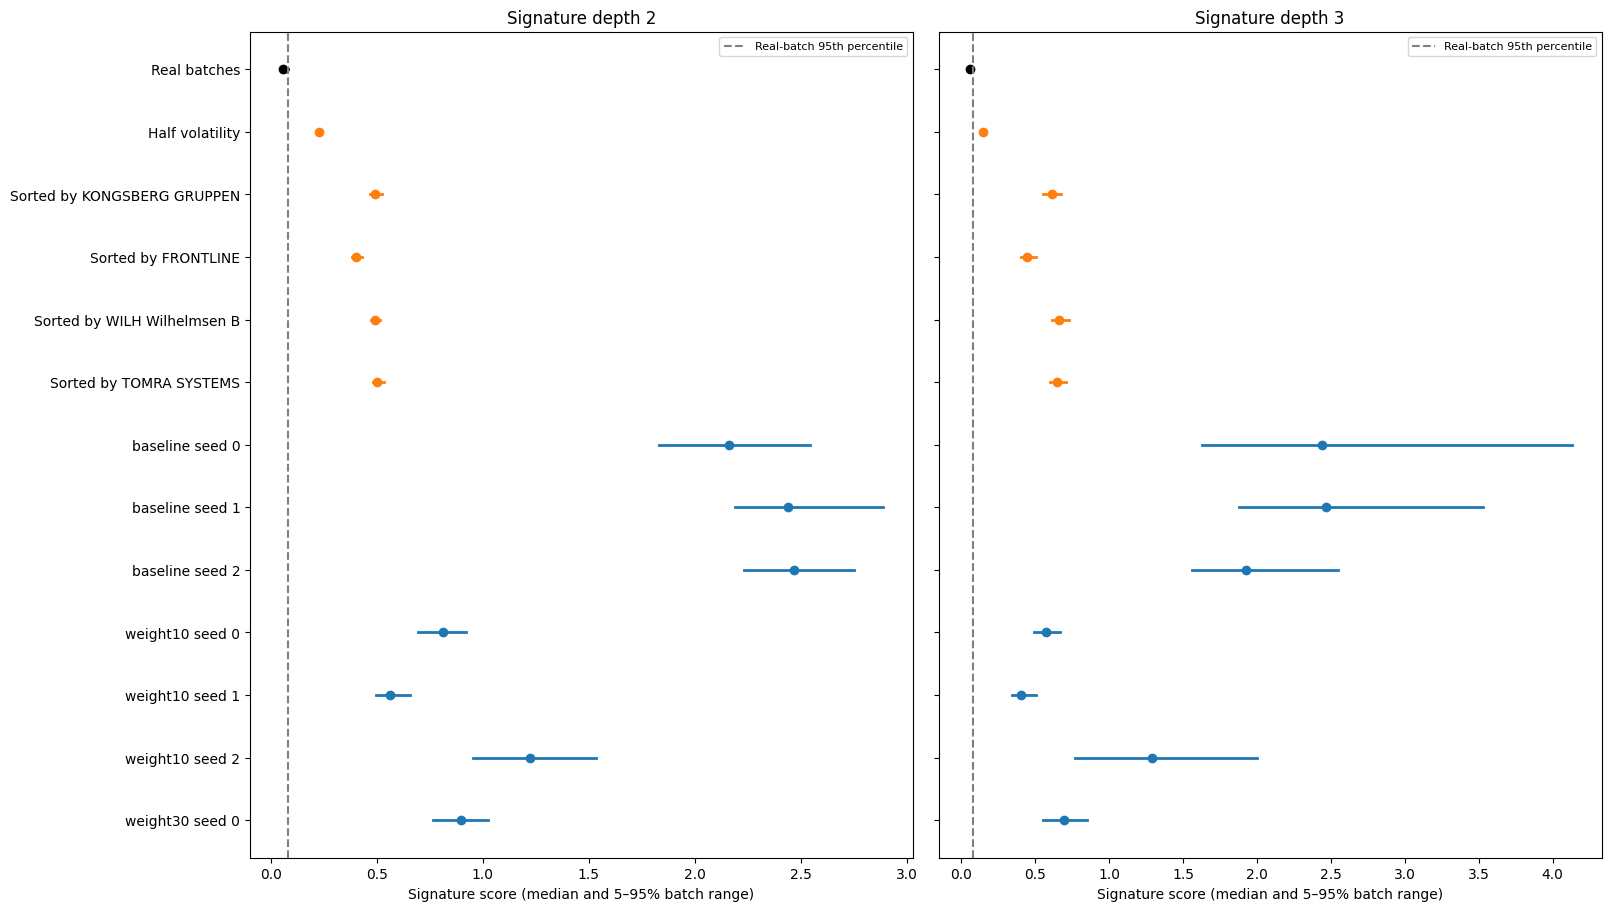

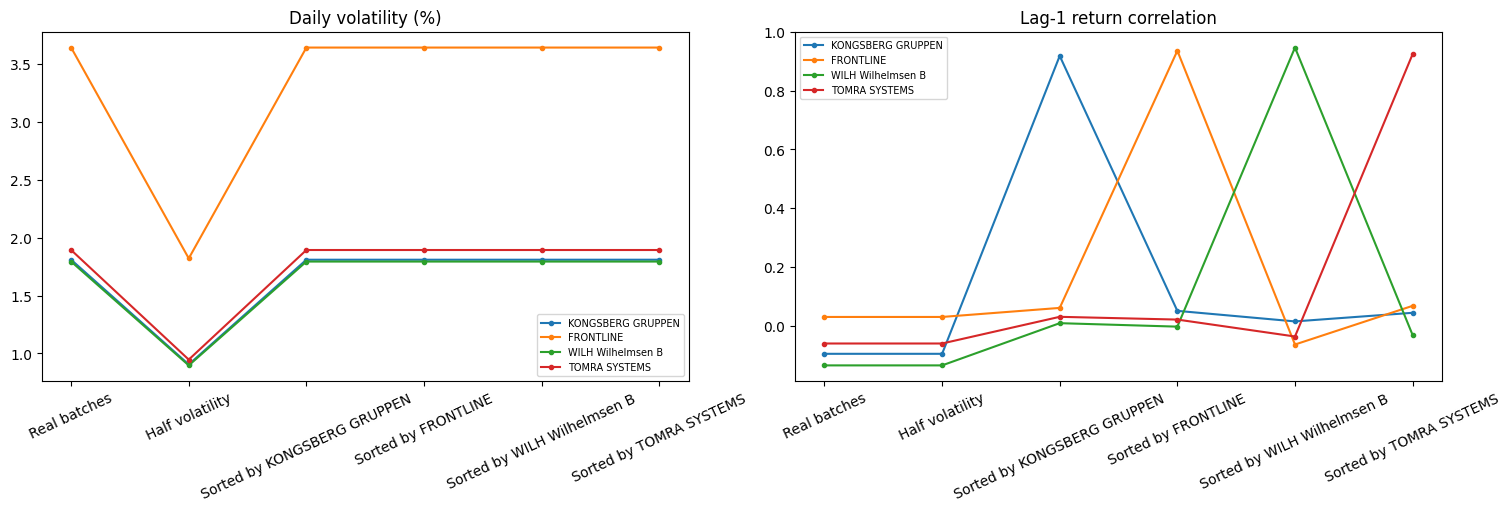

In [10]:
order = list(pools)
fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharey=True, constrained_layout=True)
for depth, ax in zip(DEPTHS, axes):
    table = summary.loc[summary.depth.eq(depth)].set_index("dataset").loc[order]
    y = np.arange(len(order))
    for i, key in enumerate(order):
        row = table.loc[key]
        color = "black" if key == "real" else "tab:orange" if key in ["half_volatility", *[f"sorted_{j}" for j in range(4)]] else "tab:blue"
        ax.plot([row.batch_q05, row.batch_q95], [i, i], color=color, linewidth=2)
        ax.scatter(row.median_score, i, color=color)
    ax.axvline(table.loc["real", "real_batch_q95"], color="grey", linestyle="--", label="Real-batch 95th percentile")
    ax.set(title=f"Signature depth {depth}", xlabel="Signature score (median and 5–95% batch range)",
           yticks=y, yticklabels=[labels[k] for k in order])
    ax.legend(fontsize=8)
axes[0].invert_yaxis()
fig.savefig(out_dir / "signature_detection.png", dpi=150)
plt.show()
plt.close(fig)
# Show the verified distortions beside their signature scores.
control_metrics = metrics.loc[metrics.dataset.isin(["real", "half_volatility", *[f"sorted_{j}" for j in range(4)]])]
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for stock in STOCKS:
    table = control_metrics.loc[control_metrics.stock.eq(stock)].set_index("dataset").loc[order[:6]]
    axes[0].plot(range(6), table.daily_volatility_pct, marker=".", label=stock)
    axes[1].plot(range(6), table.lag1_acf, marker=".", label=stock)
for ax, title in zip(axes, ["Daily volatility (%)", "Lag-1 return correlation"]):
    ax.set(title=title, xticks=range(6), xticklabels=[labels[k] for k in order[:6]])
    ax.tick_params(axis="x", rotation=25)
    ax.legend(fontsize=7)
fig.savefig(out_dir / "control_checks.png", dpi=150)
plt.show()
plt.close(fig)

## Read the result

A control consistently above real-data batch scores shows that the features
notice that distortion. Catching these severe controls does not prove they
catch every ACF error or will improve training. Read the existing-model scores
alongside their measured volatility and ACF, rather than declaring a winner
from signatures alone.

In [11]:
controls = summary.loc[summary.dataset.isin(["half_volatility", *[f"sorted_{j}" for j in range(4)]])]
print("Fraction of altered batches above the real-data 95th-percentile score:")
display(controls.pivot(index="label", columns="depth", values="fraction_above_real_q95"))
for depth in DEPTHS:
    rows = controls.loc[controls.depth.eq(depth)]
    detected = rows.loc[rows.fraction_above_real_q95.ge(.90), "label"].tolist()
    print(f"Depth {depth}: {len(detected)} of {len(rows)} controls exceed the reference in at least 90% of batches.")
settings = {
    "sample_seed": SAMPLE_SEED, "n_generated": N_GENERATED, "batch_seed": BATCH_SEED,
    "batch_size": BATCH_SIZE, "batch_repeats": BATCH_REPEATS, "depths": DEPTHS,
    "signature_channels": channels, "feature_std_min": FEATURE_STD_MIN,
    "embedding": "cumulative training-standardized log returns, zero basepoint, joint lead-lag, normalized time",
    "score": "RMS difference of mean signature coordinates scaled by training feature std",
    "constant_features": "ignored", "controls": labels,
    "reference": "all retained training windows; conditional empirical-batch calibration",
    "preprocessing": reference_metadata, "models": model_records,
    "numpy_version": version("numpy"), "jax_version": version("jax"),
}
(out_dir / "signature_setup.json").write_text(json.dumps(settings, indent=2, allow_nan=False) + "\n")
print(f"Saved tables, feature scaler, settings, and figures to {out_dir}")

Fraction of altered batches above the real-data 95th-percentile score:


depth,2,3
label,,
Half volatility,1.0,1.0
Sorted by FRONTLINE,1.0,1.0
Sorted by KONGSBERG GRUPPEN,1.0,1.0
Sorted by TOMRA SYSTEMS,1.0,1.0
Sorted by WILH Wilhelmsen B,1.0,1.0


Depth 2: 5 of 5 controls exceed the reference in at least 90% of batches.
Depth 3: 5 of 5 controls exceed the reference in at least 90% of batches.
Saved tables, feature scaler, settings, and figures to /Users/pasha/Desktop/master/master_thesis/sandbox/4stocks_experiment/results/signature_diagnostics
